In [50]:
%pylab inline
from astropy.table import Table, vstack
import astropy.io.fits as pyfits

import matplotlib
import matplotlib.patches as mpatches

import lsst.afw.image as afwImage
import lsst.afw.table as afwTable

Populating the interactive namespace from numpy and matplotlib


# Comaprison between S16 S18 and S19

# Difference 1: Detection number difference
![](wrkDir/s18-2/plot/spacial/num_mag.png)

### The left panel is the total number in S16A FDFC region with only magnitude cut and pixel flag masks. WL cut further appied and the total number is shown in the right panel. 

----------------------------------------------------------------------

```sql
NOT meas_ireprocess.i_deblend_skipped                   AND
NOT meas_ireprocess.i_sdsscentroid_flag                 AND
NOT meas_ireprocess.i_pixelflags_edge                   AND
NOT meas_ireprocess.i_pixelflags_interpolatedcenter     AND
NOT meas_ireprocess.i_pixelflags_saturatedcenter        AND
NOT meas_ireprocess.i_pixelflags_crcenter               AND
NOT meas_ireprocess.i_pixelflags_bad                    AND
NOT meas_ireprocess.i_pixelflags_suspectcenter          AND
NOT meas_ireprocess.i_pixelflags_clipped                AND
meas_ireprocess.i_detect_isprimary                      AND
NOT meas_ireprocess.i_hsmshaperegauss_flag              AND
meas.i_extendedness_value != 0                          AND
 -- In postgres, all numbers are comparable including NaN
meas_ireprocess.i_hsmshaperegauss_sigma != 'NaN'
```

INTRP 2
CR 3
INEXACT_PSF 12
REJECTED 14
SENSOR_EDGE 15


---------------------------------------

![](wrkDir/s18-2/plot/spacial/s18-ratio-numMap-obs.png)
![](wrkDir/s18-2/plot/spacial/s18-ratio-hist-obs.png)


![](wrkDir/s18-2/plot/spacial/s19-ratio-numMap-obs.png)
![](wrkDir/s18-2/plot/spacial/s19-ratio-hist-obs.png)

# Difference 2: Measurement difference

## snr-res histogram after WL cut

![](galDis-s16-s18-s19-append.png)

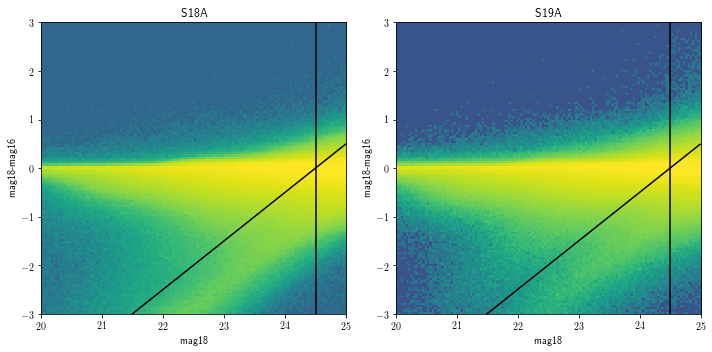

In [131]:
dat18=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-dmag-mag_s18-all-all.fits')
dat19=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-dmag-mag_s19-all-all.fits')
def makeMagdMagPlot(data,ax,title):
    bdry    =   np.percentile(data,np.arange(0,101,1))
    norm2   =   matplotlib.colors.BoundaryNorm(bdry,ncolors=256)
    dextent =   [20,25,-3,3]
    ax.set_xlim(20,25)
    ax.set_ylim(-3,3)
    im      =   ax.imshow(data,extent=dextent,norm=norm2,origin='lower',aspect='auto')
    x=np.arange(20,25.,0.01)
    y=x-24.5
    ax.plot(x,y,c='black')
    axvline(24.5,c='black')
    ax.set_title(title)
    return
fig     =   plt.figure(figsize=(10, 5))
ax      =   fig.add_subplot(1,2,1)
ax.set_xlabel('mag18')
ax.set_ylabel('mag18-mag16')
makeMagdMagPlot(dat18,ax,'S18A')
ax      =   fig.add_subplot(1,2,2)
ax.set_xlabel('mag18')
ax.set_ylabel('mag18-mag16')
makeMagdMagPlot(dat19,ax,'S19A')
plt.tight_layout()
plt.show()

```python
match   =   smatch.match(data16['ra'],data16['dec'],0.4/3600.,\
    data18['ra'],data18['dec'],maxmatch=1)
index   =   np.unique(match['i1'],return_index=True)[1]
match   =   match[index]
```

# Reason 1: unrecongnized potential blending !

In [51]:
img16=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s16/gal-0.fits')
img18=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s18/gal-0.fits')
img19=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s19/gal-0.fits')
cat=Table.read('wrkDir/exfaGalAll-noiRep-srcInser/s16/cat-0.csv')

In [65]:
imgO16=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-0.fits')
imgO18=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-0.fits')
imgO19=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-0.fits')

msk16=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-0.fits').astype(int)
msk18=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-0.fits').astype(int)
msk19=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-0.fits').astype(int)


imgO162=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-1.fits')
imgO182=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-1.fits')
imgO192=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-1.fits')

msk162=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-1.fits').astype(int)
msk182=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-1.fits').astype(int)
msk192=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-1.fits').astype(int)

24.71834945678711 65


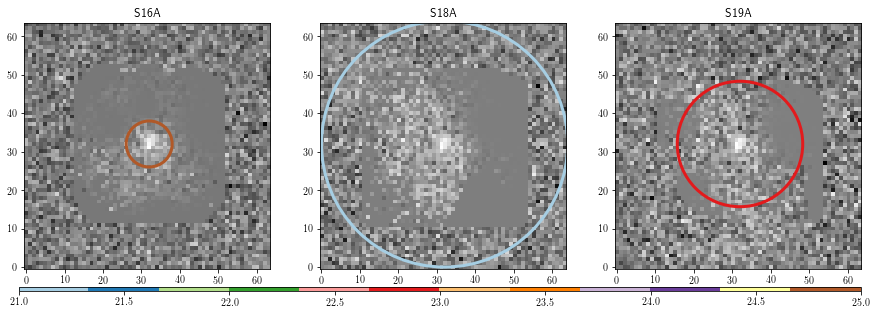

In [156]:
il=np.where((cat['mag16']-cat['mag'])>2.5)[0]
j=2
i=il[j]
ss=cat[i]
print(ss['mag16'],len(il))
ngrid=64
xy  =   (ngrid//2,ngrid//2)
cmap    =   plt.cm.Paired
norm    =   matplotlib.colors.Normalize(vmin=21,vmax=25.)
mappable=   plt.cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array([])

fig =   plt.figure(figsize=(15, 5))

ax  =   fig.add_subplot(1,3,1)
ax.set_title('S16A')
rg  =   min(ss['traceR16']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag16']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img16[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,2)
ax.set_title('S18A')
rg  =   min(ss['traceR']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img18[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,3)
ax.set_title('S19A')
rg  =   min(ss['traceR19']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag19']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img19[i],origin='lower',cmap='Greys_r')
cbar_ax     =   fig.add_axes([0.12, 0.1, 0.78, 0.01])
fig.colorbar(mappable,cbar_ax,orientation='horizontal')
plt.show()

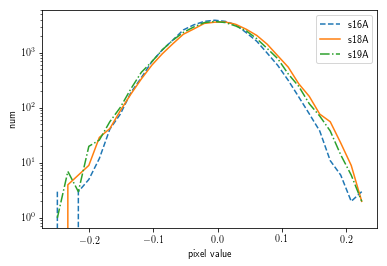

In [157]:
bg16=[]
bg18=[]
bg19=[]
for j in range(10):
    i=il[j]
    mask1=(msk19[i]==0)& (msk18[i]==0) & (msk16[i]==0)
    bg16.extend(imgO16[i][mask1])
    bg18.extend(imgO18[i][mask1])
    bg19.extend(imgO19[i][mask1])
    mask2=(msk192[i]==0)& (msk182[i]==0) & (msk162[i]==0)
    bg16.extend(imgO162[i][mask2])
    bg18.extend(imgO182[i][mask2])
    bg19.extend(imgO192[i][mask2])

h,g=np.histogram(bg16,30)
plt.plot(g[:-1],h,'--',label='s16A')
h,g=np.histogram(bg18,g)
plt.plot(g[:-1],h,'-',label='s18A')
h,g=np.histogram(bg19,g)
plt.plot(g[:-1],h,'-.',label='s19A')
plt.xlabel('pixel value')
plt.ylabel('num')
plt.yscale('log')
plt.legend()

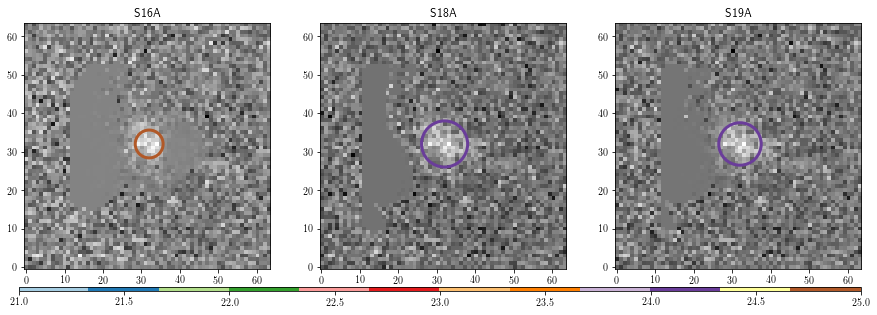

In [144]:
j=0
il=[3,4,12,13,16,20,21,25,27,32,33,37,40,0,41,43,48,50,10,11,18,24]
i=il[j]
ss=cat[i]
ngrid=64
xy  =   (ngrid//2,ngrid//2)
cmap    =   plt.cm.Paired
norm    =   matplotlib.colors.Normalize(vmin=21,vmax=25.)
mappable=   plt.cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array([])

fig =   plt.figure(figsize=(15, 5))

ax  =   fig.add_subplot(1,3,1)
ax.set_title('S16A')
rg  =   min(ss['traceR16']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag16']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img16[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,2)
ax.set_title('S18A')
rg  =   min(ss['traceR']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img18[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,3)
ax.set_title('S19A')
rg  =   min(ss['traceR19']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag19']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img19[i],origin='lower',cmap='Greys_r')
cbar_ax     =   fig.add_axes([0.12, 0.1, 0.78, 0.01])
fig.colorbar(mappable,cbar_ax,orientation='horizontal')
plt.show()

* larger resolution
* brighter magnitude
* more sources (\# S19 < \# S16)

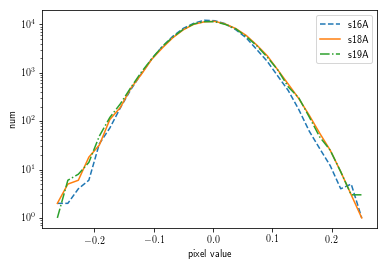

In [121]:
bg16=[]
bg18=[]
bg19=[]
for j in range(22):
    i=il[j]
    mask1=(msk19[i]==0)& (msk18[i]==0) & (msk16[i]==0)
    bg16.extend(imgO16[i][mask1])
    bg18.extend(imgO18[i][mask1])
    bg19.extend(imgO19[i][mask1])
    mask2=(msk192[i]==0)& (msk182[i]==0) & (msk162[i]==0)
    bg16.extend(imgO162[i][mask2])
    bg18.extend(imgO182[i][mask2])
    bg19.extend(imgO192[i][mask2])

h,g=np.histogram(bg16,30)
plt.plot(g[:-1],h,'--',label='s16A')
h,g=np.histogram(bg18,g)
plt.plot(g[:-1],h,'-',label='s18A')
h,g=np.histogram(bg19,g)
plt.plot(g[:-1],h,'-.',label='s19A')
plt.xlabel('pixel value')
plt.ylabel('num')
plt.yscale('log')
plt.legend()

# Reason 2: background residuals

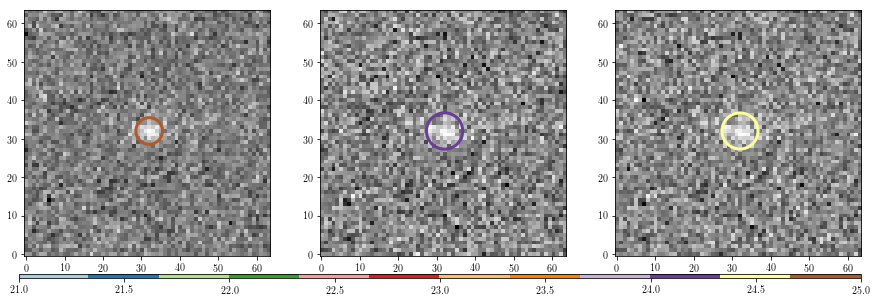

In [123]:
j=3
il=[1,29,31,35,37,39,42,44,45,46,47,49]#il=[17,19,23]

i=il[j]
ss=cat[i]
ngrid=64
xy  =   (ngrid//2,ngrid//2)
cmap    =   plt.cm.Paired
norm    =   matplotlib.colors.Normalize(vmin=21,vmax=25.)
mappable=   plt.cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array([])

fig =   plt.figure(figsize=(15, 5))
ax  =   fig.add_subplot(1,3,1)

rg  =   min(ss['traceR16']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag16']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img16[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,2)
rg  =   min(ss['traceR']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img18[i],origin='lower',cmap='Greys_r')

ax  =   fig.add_subplot(1,3,3)
rg  =   min(ss['traceR19']/0.168,ngrid//2)
clr =   cmap(norm(ss['mag19']))
cir =   mpatches.Circle(xy,radius=rg,ls='-',facecolor='None',edgecolor=clr,lw=3.)
ax.add_patch(cir)
im  =   ax.imshow(img19[i],origin='lower',cmap='Greys_r')
cbar_ax     =   fig.add_axes([0.12, 0.1, 0.78, 0.01])
fig.colorbar(mappable,cbar_ax,orientation='horizontal')
plt.show()

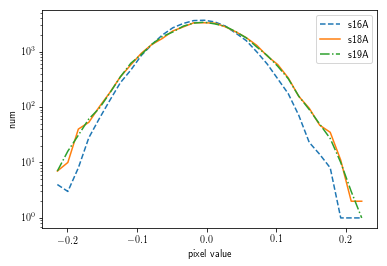

In [124]:
bg16=[]
bg18=[]
bg19=[]
for j in range(10):
    i=il[j]
    mask1=(msk19[i]==0)& (msk18[i]==0) & (msk16[i]==0)
    bg16.extend(imgO16[i][mask1])
    bg18.extend(imgO18[i][mask1])
    bg19.extend(imgO19[i][mask1])
    mask2=(msk192[i]==0)& (msk182[i]==0) & (msk162[i]==0)
    bg16.extend(imgO162[i][mask2])
    bg18.extend(imgO182[i][mask2])
    bg19.extend(imgO192[i][mask2])

h,g=np.histogram(bg16,30)
plt.plot(g[:-1],h,'--',label='s16A')
h,g=np.histogram(bg18,g)
plt.plot(g[:-1],h,'-',label='s18A')
h,g=np.histogram(bg19,g)
plt.plot(g[:-1],h,'-.',label='s19A')
plt.xlabel('pixel value')
plt.ylabel('num')
plt.yscale('log')
plt.legend()

In [40]:
a=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s18.fits')
b=pyfits.getdata('./wrkDir/database/compare/scat-s18-unmatch-s16.fits')
a2=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s19.fits')

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:6: RuntimeWarning: invalid value encountered in less
  
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in less
  import sys
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in less
  


In [76]:
maskA=(a['mag']<19)&(a['res']>0.3)&(a['logb']<-0.38)&(a['TPid']==9696502)
maskB=(b['mag']<19)&(b['res']>0.3)&(b['logb']<-0.38)&(b['TPid']==9696502)
maskA2=(a2['mag']<19)&(a2['res']>0.3)&(a2['logb']<-0.38)&(a2['TPid']==9696502)
aM=a[maskA]
bM=b[maskB]
aM2=a2[maskA2]

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in less
  """Entry point for launching an IPython kernel.
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:2: RuntimeWarning: invalid value encountered in less
  
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in less
  This is separate from the ipykernel package so we can avoid doing imports until


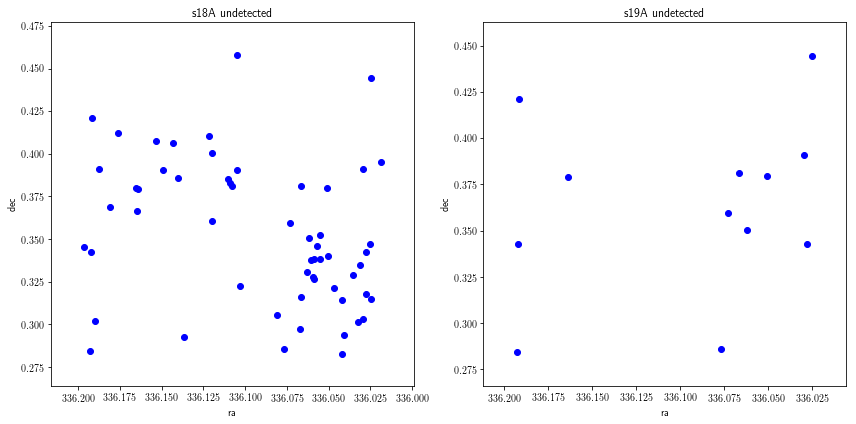

In [77]:
fig=    plt.figure(figsize=(12, 6))
ax =    fig.add_subplot(1,2,1)
ax.scatter(aM['ra'],aM['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s18A undetected')
ax =    fig.add_subplot(1,2,2)
ax.scatter(aM2['ra'],aM2['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s19A undetected')
plt.tight_layout()

### This left (right) panel shows the galaxies in S16A WL with $mag \lt 19$ which do not have corresponding match within 0.4 arcsec in S18A ( S19A)


![](undetect-brightGal-1.png)

![](undetect-brightGal-2.png)

# Solution

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.9.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.8.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.7.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.6.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.5.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.4.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.3.png)

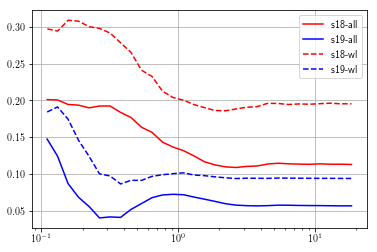

In [179]:
import astropy.io.ascii as ascii
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['kappa'],c='blue',label='s19-all')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls='--',label='s19-wl')
plt.xscale('log')
plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

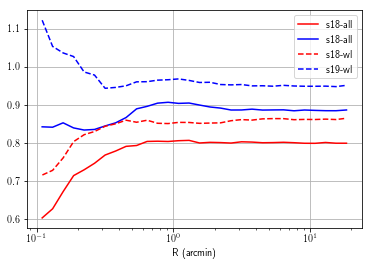

In [174]:
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',label='s18-all')

d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',ls='--',label='s19-wl')
plt.legend()
plt.grid()
plt.xscale('log')
plt.xlabel('R (arcmin)')